# Train the last layer

## Imports 

In [1]:
import sys
import os
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), "/home/f24achba/Documents/Edge AI/52-Hertz-KWS/src")))

In [2]:
import tensorflow as tf
import numpy as np
import os, glob
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from preprocessing import AudioPipeline
from preprocessing.dataset_pipeline import load_and_preprocess, make_dataset
from preprocessing.transfer_model import build_transfer_model
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import StratifiedShuffleSplit

I0000 00:00:1781082001.605857   15850 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1781082001.632434   15850 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1781082002.376816   15850 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


## Config

In [3]:
DATA_DIR    = "/home/f24achba/Documents/Edge AI/52-Hertz-KWS/data/raw"
CLASSES     = ["talky", "silence", "unknown"]
BATCH_SIZE  = 16      
EPOCHS   = 40       # backbone gelé
LR       = 1e-3
SEED       = 42
KERAS_PATH  = "/home/f24achba/Documents/Edge AI/52-Hertz-KWS/src/models/miniresnetv2_s1_64x50_tl.keras"

pipeline = AudioPipeline("/home/f24achba/Documents/Edge AI/52-Hertz-KWS/configuration/config.yaml")

## Chargement des chemins + labels 

In [4]:
all_paths, all_labels = [], []

for label_idx, class_name in enumerate(CLASSES):
    wavs = glob.glob(os.path.join(DATA_DIR, class_name, "*.wav"))
    all_paths  += wavs
    all_labels += [label_idx] * len(wavs)
    print(f"  {class_name:10s} → {len(wavs)} fichiers")

all_paths  = np.array(all_paths)
all_labels = np.array(all_labels)
print(f"\nTotal : {len(all_paths)} samples\n")

  talky      → 295 fichiers
  silence    → 135 fichiers
  unknown    → 326 fichiers

Total : 756 samples



## Split : on utilise un k-fold stratifié (On utilise 85% pour entraîner car il n'y a plus de test set : la k-fold a déjà joué ce rôle.)

In [5]:
sss = StratifiedShuffleSplit(n_splits=1, test_size=0.15, random_state=42)
train_idx, val_idx = next(sss.split(all_paths, all_labels))
 
X_train_final = all_paths[train_idx]
y_train_final = all_labels[train_idx]
X_val_final   = all_paths[val_idx]
y_val_final   = all_labels[val_idx]
 
print(f"Train final : {len(X_train_final)} samples")
print(f"Val   final : {len(X_val_final)} samples")
for i, cls in enumerate(CLASSES):
    n_tr = np.sum(y_train_final == i)
    n_vl = np.sum(y_val_final   == i)
    print(f"  {cls:10s} → train={n_tr}  val={n_vl}")
 

Train final : 642 samples
Val   final : 114 samples
  talky      → train=250  val=45
  silence    → train=115  val=20
  unknown    → train=277  val=49


## Class weights 

In [6]:
class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(y_train_final),
    y=y_train_final
)
class_weight_dict_final = dict(enumerate(class_weights))
print(f"\nClass weights : {class_weight_dict_final}")



Class weights : {0: 0.856, 1: 1.8608695652173912, 2: 0.7725631768953068}


## tf.data pipeline 

In [7]:
train_ds = make_dataset(X_train_final, y_train_final, BATCH_SIZE, augment=True)
val_ds   = make_dataset(X_val_final,   y_val_final, BATCH_SIZE,  augment=False)

W0000 00:00:1781082003.088296   15910 cuda_executor.cc:1755] Failed to determine cuDNN version (Note that this is expected if the application doesn't link the cuDNN plugin): INTERNAL: cuDNN error: CUDNN_STATUS_INTERNAL_ERROR
W0000 00:00:1781082003.126095   15850 gpu_device.cc:2365] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


## model 

In [8]:
tf.keras.backend.clear_session() 
model = build_transfer_model(KERAS_PATH, num_classes=3)
model.compile(
    optimizer=tf.keras.optimizers.Adam(LR),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

## Callbacks 

In [9]:
DEPLOY_PATH = "final_model_deploy.keras"
 
callbacks_final = [
    tf.keras.callbacks.ModelCheckpoint(
        DEPLOY_PATH,
        monitor="val_accuracy",
        save_best_only=True,
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=12,                # même valeur que la k-fold
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=4,
        min_lr=1e-6,
        verbose=1
    ),
    tf.keras.callbacks.TensorBoard(log_dir="./logs_final")
]


## Training

In [10]:
print("\n Entraînement final (modèle de déploiement)")
 
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks_final,
    class_weight=class_weight_dict_final
)



 Entraînement final (modèle de déploiement)
Epoch 1/40
34/41 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.3707 - loss: 1.0939
Epoch 1: val_accuracy improved from None to 0.28947, saving model to final_model_deploy.keras
41/41 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - accuracy: 0.3645 - loss: 1.0971 - val_accuracy: 0.2895 - val_loss: 1.0957 - learning_rate: 0.0010
Epoch 2/40
33/41 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.3697 - loss: 1.0785
Epoch 2: val_accuracy improved from 0.28947 to 0.54386, saving model to final_model_deploy.keras
41/41 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.4315 - loss: 1.0698 - val_accuracy: 0.5439 - val_loss: 1.0602 - learning_rate: 0.0010
Epoch 3/40
32/41 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.4585 - loss: 1.0752
Epoch 3: val_accuracy improved from 0.54386 to 0.87719, saving model to final_model_deploy.keras
41/41 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.5218 - loss: 1.0520 - val_accuracy: 0.8772 - val_loss: 1.0429 - learning_rate: 0.

## Evaluation

In [11]:
model_final = tf.keras.models.load_model(DEPLOY_PATH)
loss_f, acc_f = model_final.evaluate(val_ds, verbose=0)
 
best_epoch_f   = int(np.argmax(history.history["val_accuracy"])) + 1
best_val_acc_f = float(np.max(history.history["val_accuracy"]))
 
print(f"\n Val accuracy  : {acc_f:.4f}")
print(f" Best epoch    : {best_epoch_f}")
print(f" Modèle sauvegardé → {DEPLOY_PATH}")



 Val accuracy  : 0.9386
 Best epoch    : 11
 Modèle sauvegardé → final_model_deploy.keras


## Classification report

In [12]:
y_pred_f = np.argmax(model_final.predict(val_ds), axis=1)
y_true_f = np.concatenate([y for _, y in val_ds], axis=0)
print("\n" + classification_report(y_true_f, y_pred_f, target_names=CLASSES))

8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step

              precision    recall  f1-score   support

       talky       0.98      0.98      0.98        45
     silence       0.89      0.85      0.87        20
     unknown       0.92      0.94      0.93        49

    accuracy                           0.94       114
   macro avg       0.93      0.92      0.93       114
weighted avg       0.94      0.94      0.94       114



## Tester les moments de convergence

In [13]:
best_epoch = np.argmax(history.history["val_accuracy"]) + 1
best_val_acc = np.max(history.history["val_accuracy"])

print(f"Best Epoch : {best_epoch}")
print(f"Val Acc : {best_val_acc})")

Best Epoch : 11
Val Acc : 0.9385964870452881)


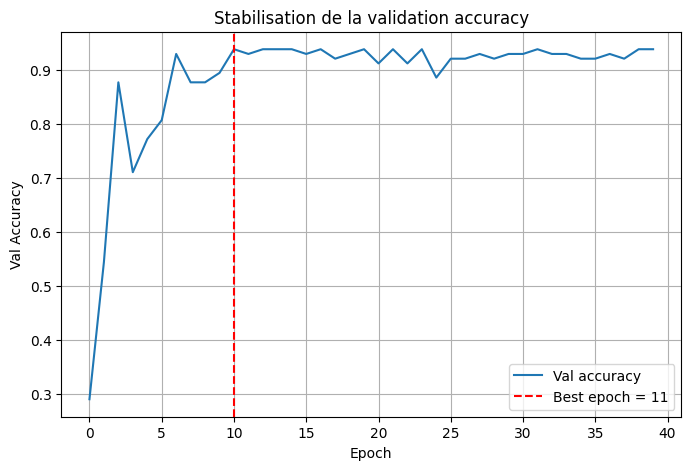

Best val acc: 0.9385964870452881


In [14]:
import numpy as np
import matplotlib.pyplot as plt

val_acc = history.history["val_accuracy"]
best_epoch = np.argmax(val_acc)

plt.figure(figsize=(8,5))

plt.plot(val_acc, label="Val accuracy")
plt.axvline(best_epoch, color="red", linestyle="--", label=f"Best epoch = {best_epoch+1}")

plt.xlabel("Epoch")
plt.ylabel("Val Accuracy")
plt.title("Stabilisation de la validation accuracy")
plt.legend()
plt.grid(True)

plt.show()

print("Best val acc:", val_acc[best_epoch])


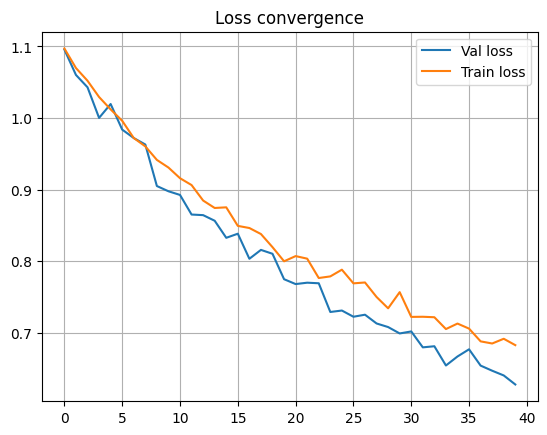

In [15]:
plt.plot(history.history["val_loss"], label="Val loss")
plt.plot(history.history["loss"], label="Train loss")
plt.legend()
plt.grid()
plt.title("Loss convergence")
plt.show()